# Exploratory Data Analysis — Job Market Intelligence

This notebook has **two parts**:

* **Part A – Raw data EDA.** Look at the raw files *before* cleaning to discover the problems
  (missing values, duplicates, wrong countries, mixed formats). Every problem found here has a
  matching rule in `src/clean_utils.py` / `src/pipeline.py`.
* **Part B – Clean data EDA.** Explore `data/processed/jobs_clean.csv` produced by
  `python src/pipeline.py`: where the opportunities are and which skills they ask for.

> Run `python src/pipeline.py` once before running Part B.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import clean_utils as cu
from loaders import LOADERS

pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 60)

# --- chart style --------------------------------------------------------------
# One fixed color per market type (never re-assigned by rank), one hue for counts.
MARKET_COLORS = {"Arab": "#2a78d6", "International": "#eb6834", "Remote": "#1baf7a"}
BAR = "#2a78d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})


def hbar(series, title, xlabel="postings", color=BAR, ax=None, fmt="{:,.0f}"):
    '''Horizontal bar chart, largest on top, value labels at the bar ends.'''
    s = series.sort_values()
    ax = ax or plt.subplots(figsize=(8, 0.32 * len(s) + 1))[1]
    ax.barh(s.index.astype(str), s.values, color=color, height=0.7)
    ax.grid(axis="y", visible=False)
    for y, v in enumerate(s.values):
        ax.text(v, y, " " + fmt.format(v), va="center", fontsize=8, color=MUTED)
    ax.set_title(title); ax.set_xlabel(xlabel)
    ax.xaxis.set_major_locator(mtick.MaxNLocator(4))
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
    return ax

---
# Part A — Raw data EDA

The raw folder holds **10 files**. Four of them exist twice: an original file and an
`_after_adding_skills` version with the **same rows** where the team filled in missing skills.
The pipeline uses the enriched file and compares it with the original to flag which skills were *added*.

We load every source with its loader from `src/loaders.py` — the loaders only rename columns
into one shared ("staging") layout, they do **not** clean anything yet.

In [2]:
raw = pd.concat([loader() for loader in LOADERS.values()], ignore_index=True)
print(f"{len(raw):,} raw rows, {raw.shape[1]} staging columns")
raw.groupby("source_dataset").size().sort_values(ascending=False).to_frame("rows")

775,155 raw rows, 23 staging columns


,rows
source_dataset,
kaggle_2023_international,705866
kaggle_2023_arab_search,38898
jooble_careerjet_foreign,18583
all_tech_jobs,6693
startup_jobs,3543
remote_boards,1075
arab_jobs,439
cybersecurity_manual,58


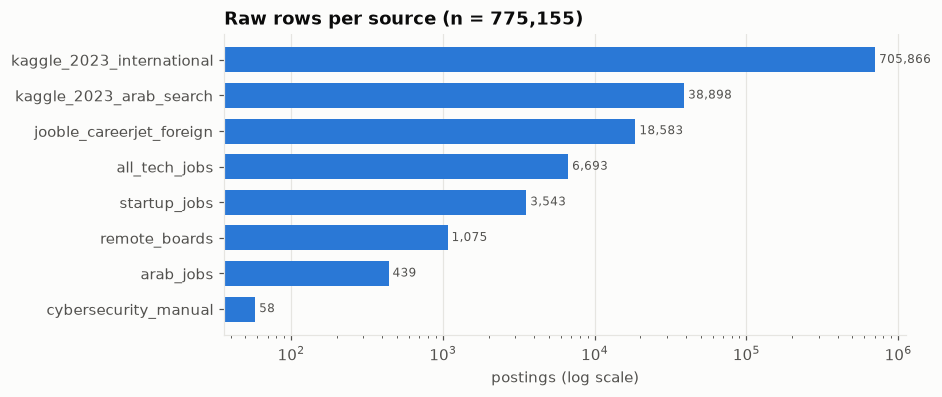

In [3]:
hbar(raw["source_dataset"].value_counts(), f"Raw rows per source (n = {len(raw):,})")
plt.xscale("log"); plt.xlabel("postings (log scale)"); plt.show()

**Observation.** One source (the Kaggle 2023 *international* dataset) holds **91 %** of all rows.
Any overall statistic will be dominated by it, so later analyses are always split by
`market_type` / `source_dataset`. Note also the **log scale**: the Arab sources are tiny (hundreds of rows).

## A1. Missing values per source

In [4]:
key = ["title", "company", "country_raw", "description", "skills_raw", "salary_text", "salary_min", "posted_raw", "url"]
missing = raw.groupby("source_dataset")[key].apply(lambda d: d.isna().mean() * 100).round(0)
missing.style.background_gradient(cmap="Blues", vmin=0, vmax=100).format("{:.0f}%")

,title,company,country_raw,description,skills_raw,salary_text,salary_min,posted_raw,url
source_dataset,,,,,,,,,
all_tech_jobs,0%,0%,1%,0%,0%,59%,100%,26%,0%
arab_jobs,0%,33%,0%,67%,0%,100%,0%,82%,80%
cybersecurity_manual,0%,0%,0%,100%,0%,0%,100%,100%,100%
jooble_careerjet_foreign,0%,1%,0%,0%,0%,72%,100%,0%,0%
kaggle_2023_arab_search,0%,0%,0%,100%,0%,55%,93%,0%,100%
kaggle_2023_international,0%,0%,0%,100%,14%,100%,96%,0%,100%
remote_boards,0%,0%,0%,0%,0%,95%,100%,0%,0%
startup_jobs,0%,0%,0%,100%,0%,55%,100%,0%,0%


**Observations.**
* `description` is missing for the whole Kaggle data, startup.jobs and the cybersecurity file —
  skills for those rows can only come from the `skills` column, not from text.
* A salary exists either as text (`salary_text`) **or** already as numbers (`salary_min`) — the
  pipeline parses the text into the same numeric fields.
* `url` is missing for the Kaggle data, so duplicates there must be found by title + company + location.

## A2. Wrong country in the merged file ("Sudan" problem)

In the merged 45k file, the second part comes from the Kaggle dataset filtered on *Arab search
locations*. Its `job_country` column is the **search location**, not the job's location:

In [5]:
m = pd.read_excel(ROOT / "data/raw/Merged_Tech_Jobs_45k_skills_enriched_AFTER_ADDING_SKILLS.xlsx",
                  usecols=["title", "location_raw", "country", "job_country", "record_origin"])
sudan = m[m["job_country"].eq("Sudan")]
print(f"{len(sudan):,} rows say job_country = 'Sudan'. Their real location:")
sudan["country"].value_counts().head(5).to_frame("rows")

21,141 rows say job_country = 'Sudan'. Their real location:


,rows
country,
United States,17065
Remote (Anywhere),3902
Other/Unknown,134
Unknown,36
Lebanon,2


**Decision.** Use the team's rebuilt `country` column (derived from the real `location_raw`),
never `job_country`. Without this fix, Sudan would look like the biggest Arab tech market.

## A3. Inconsistent formats

In [6]:
print("job_type spellings:", raw["job_type_raw"].nunique())
print(raw["job_type_raw"].value_counts().head(12).to_string())

job_type spellings: 123
job_type_raw
Full-time                   671381
Contractor                   33673
Internship                    8390
Part-time                     7542
Full-time and Part-time       6044
full-time                     3411
Full-time and Temp work       2426
Full-time and Internship      2237
Contractor and Temp work      2189
Full-time and Contractor      2172
Temp work                     2029
Full Time                     1515


In [7]:
print("Salary text examples:")
for s in raw["salary_text"].dropna().drop_duplicates().sample(12, random_state=7):
    print("  ", s)

Salary text examples:


   CA$90000 - 120000 per year
   $150,000 – $220,000 per year
   $189,000 – $283,000 per year
   £110,000 – £130,000 per year
   US$106000 - 170200 per year
   CA$49500 - 76200 per year
   $60 - $63 per hour
   €125.000 – €165.000 per year
   US$92500 - 209500 per year
   US$142792 - 170200 per year
   $144,000 – $180,000 per year
   CAD $133,000 – CAD $183,000 per year


In [8]:
print("Skills cell examples (different list formats):")
for s in raw["skills_raw"].dropna().sample(6, random_state=3):
    print("  ", s[:110])

Skills cell examples (different list formats):


   ['postgresql', 'oracle', 'unix', 'linux', 'power bi', 'tableau', 'word', 'bitbucket', 'jenkins']
   ['sql', 'python', 'r', 'looker']
   ['python', 'azure', 'pandas', 'airflow', 'jupyter', 'kubernetes']
   ['aws']
   ['python', 'postgresql', 'bigquery', 'redshift', 'snowflake', 'airflow', 'kafka', 'tableau', 'git']
   ['java', 'scala', 'python', 'sql', 'nosql', 'aws', 'redshift', 'gcp', 'snowflake', 'bigquery', 'databricks', '


**Observations → cleaning rules**
* ~100 spellings of job type (`full_time`, `['Full-Time']`, `Unbefristeter arbeitsvertrag` …) → 5 standard values (`standardize_job_type`).
* Salaries mix currencies (`$`, `US$`, `£`, `€`, `EGP`, `جنيه مصري`), ranges, `k` suffixes and periods (hour / month / year)
  → `parse_salary` + `salary_to_usd_annual`.
* Skills come as `"A, B; C"` or Python lists `"['a', 'b']"`, with different casing (`python` / `Python`) and synonyms
  (`k8s` / `Kubernetes`) → `parse_skill_list` + one display spelling per skill.

## A4. Salary provenance — posted pay vs. market benchmark

In [9]:
has_salary = raw["salary_text"].notna() | raw["salary_min"].notna()
prov = (raw[has_salary].assign(kind=lambda d: np.where(d["salary_is_estimate"].fillna(False).astype(bool),
                                                         "benchmark added by team", "posted in the ad"))
        .groupby(["source_dataset", "kind"]).size().unstack(fill_value=0))
prov

kind,benchmark added by team,posted in the ad
source_dataset,,
all_tech_jobs,2582,195
arab_jobs,296,143
cybersecurity_manual,0,58
jooble_careerjet_foreign,0,5243
kaggle_2023_arab_search,17685,2665
kaggle_2023_international,0,29257
remote_boards,0,50
startup_jobs,0,1591


**Observation.** In the merged file and the Arab file, most salaries are **market benchmarks**
(Paylab, Indeed, US BLS …) attached by the team — the same value repeats for every job with the same title
and country. They are useful for context but must **not** be treated as real pay. The clean data keeps
them with `salary_is_estimate = True`.

## A5. Skills that were added (not in the posting)

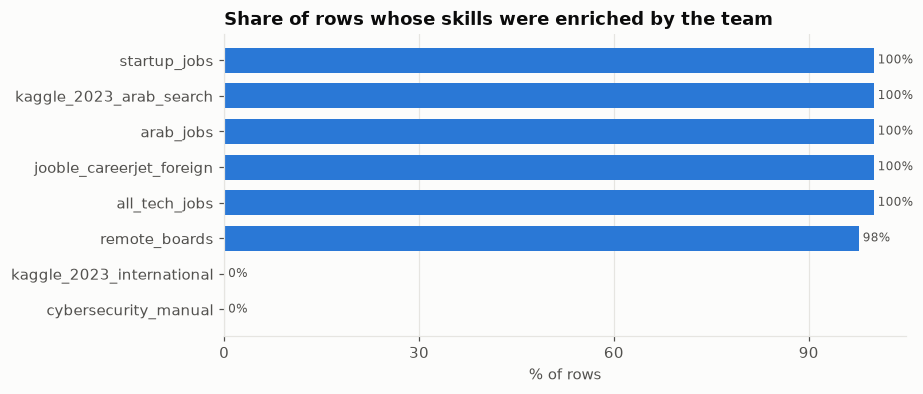

In [10]:
enr = raw.groupby("source_dataset")["skills_enriched"].apply(lambda s: s.fillna(False).astype(bool).mean() * 100)
hbar(enr.round(1), "Share of rows whose skills were enriched by the team", xlabel="% of rows", fmt="{:.0f}%")
plt.show()

**Observation.** Almost every row of the merged file has added skills, while the big Kaggle dataset has only
original skills. For a strict *"what do employers ask for?"* analysis use `skills_enriched == False`.

## A6. Duplicates

In [11]:
exact = raw.duplicated(subset=["title", "company", "location", "description", "skills_raw", "posted_raw", "url"]).sum()
k = cu.match_key(raw["title"]) + "|" + cu.match_key(raw["company"]) + "|" + cu.match_key(raw["location"])
near = k.duplicated().sum()
print(f"exact duplicate rows        : {exact:,}")
print(f"same title+company+location : {near:,}  ({near / len(raw):.0%} of rows)")
raw.assign(k=k)[k.duplicated(keep=False)].sort_values("k")[["source_dataset", "source_platform", "title", "company", "location"]].head(8)

exact duplicate rows        : 665
same title+company+location : 191,810  (25% of rows)


,source_dataset,source_platform,title,company,location
274170,kaggle_2023_international,BeBee,00 - Junior Data Scientist,ADHR GROUP SPA,"Turin, Metropolitan City of Turin, Italy"
413694,kaggle_2023_international,Trabajo. Org,00 - Junior Data Scientist,ADHR GROUP SPA,"Turin, Metropolitan City of Turin, Italy"
371497,kaggle_2023_international,Jobrapido.com,(00335) Especialista Machine Learning Engineer,MAPFRE,"Madrid, Spain"
302278,kaggle_2023_international,Trabajo.org,(00335) Especialista Machine Learning Engineer,Mapfre,"Madrid, Spain"
167955,kaggle_2023_international,Recruit.net,[0132] - Claim Data Analyst,ATI Business Group,Indonesia
307682,kaggle_2023_international,LinkedIn,[0132] - Claim Data Analyst,ATI Business Group,Indonesia
318667,kaggle_2023_international,BeBee,024873 - Data Scientist Full-remote,HUNTERS GROUP,"Naples, Metropolitan City of Naples, Italy"
357854,kaggle_2023_international,SimplyHired,024873 - Data Scientist Full-remote,HUNTERS GROUP,"Naples, Metropolitan City of Naples, Italy"


**Observation.** Exact duplicates are rare, but **near duplicates are ~24 %**: the same job is re-posted on
LinkedIn, BeBee, Indeed … or returned by Jooble for several search keywords (each time with a new tracking URL).
The pipeline keeps the most informative copy and records every platform in `sources` and the copy count in
`duplicate_count`. For placeholder companies (`Confidential`, `Emprego`, `Dice` …) the date and description are
also compared, so different hidden jobs are not merged.

## A7. Text quality: broken encoding and personal data

In [12]:
text = raw["title"].fillna("") + " " + raw["description"].fillna("")
print("rows with broken encoding (mojibake, e.g. 'Weâ€™re'):", f"{text.str.contains('â€|Ã©|Ã¨').sum():,}")
print("descriptions with an email address               :", f"{raw['description'].fillna('').str.contains(cu.EMAIL_RE).sum():,}")
print("descriptions with a phone number                 :", f"{raw['description'].fillna('').str.contains(cu.PHONE_RE).sum():,}")
print("rows with Arabic characters                      :", f"{text.str.contains('[\u0600-\u06FF]').sum():,}")

rows with broken encoding (mojibake, e.g. 'Weâ€™re'): 17


descriptions with an email address               : 315


descriptions with a phone number                 : 48


rows with Arabic characters                      : 550


**Rules.** `ftfy` repairs the broken encoding; emails / phone numbers are replaced by `[email]` / `[phone]`
(FR-06, NFR-05); Arabic text is normalized (diacritics, tatweel, أ/إ/آ → ا, ى → ي, Arabic digits → 0-9).

In [13]:
del raw, m, text, k   # free memory before Part B

---
# Part B — Clean data EDA

In [14]:
df = pd.read_csv(ROOT / "data/processed/jobs_clean.csv", low_memory=False)
skills = pd.read_csv(ROOT / "data/processed/job_skills.csv")
print(f"{len(df):,} clean postings x {df.shape[1]} columns  |  {len(skills):,} (job, skill) pairs")
df.head(3).T

588,545 clean postings x 32 columns  |  3,041,889 (job, skill) pairs


,0,1,2
job_id,ad407fffa865661e,d8db83c4f0ea01dd,c64167240de5d8f8
title,Senior Software Engineer - SRE,Senior Software Engineer - SRE,Senior Software Engineer - SRE
company,veeva,veeva,veeva
role_category,DevOps & Cloud,DevOps & Cloud,DevOps & Cloud
seniority,Senior,Senior,Senior
country,Hungary,Poland,Germany
city,Hungary - Budapest,Poland - Cracow,Germany - Berlin
location,Hungary - Budapest,Poland - Cracow,Germany - Berlin
region,Non-Arab,Non-Arab,Non-Arab
market_type,International,International,International


In [15]:
print((ROOT / "reports/data_quality_report.md").read_text(encoding="utf-8").split("## Per source")[0])

# Data Quality Report

Generated by `src/pipeline.py` on 2026-10-25 15:26.

## Record counts per pipeline stage

| stage                                                       |   rows |
|:------------------------------------------------------------|-------:|
| 1. raw rows loaded (all sources)                            | 775155 |
| 2-5. after cleaning & standardizing (no rows removed)       | 775155 |
| 6. after dropping missing-title & non-tech rows             | 773374 |
| 7a. after removing exact duplicates                         | 770956 |
| 7b. after removing near-duplicates (title+company+location) | 588545 |

Rows dropped before deduplication: missing title: 5, non-tech roles (FR-10): 1,776




## B1. Where are the opportunities? (US-01)

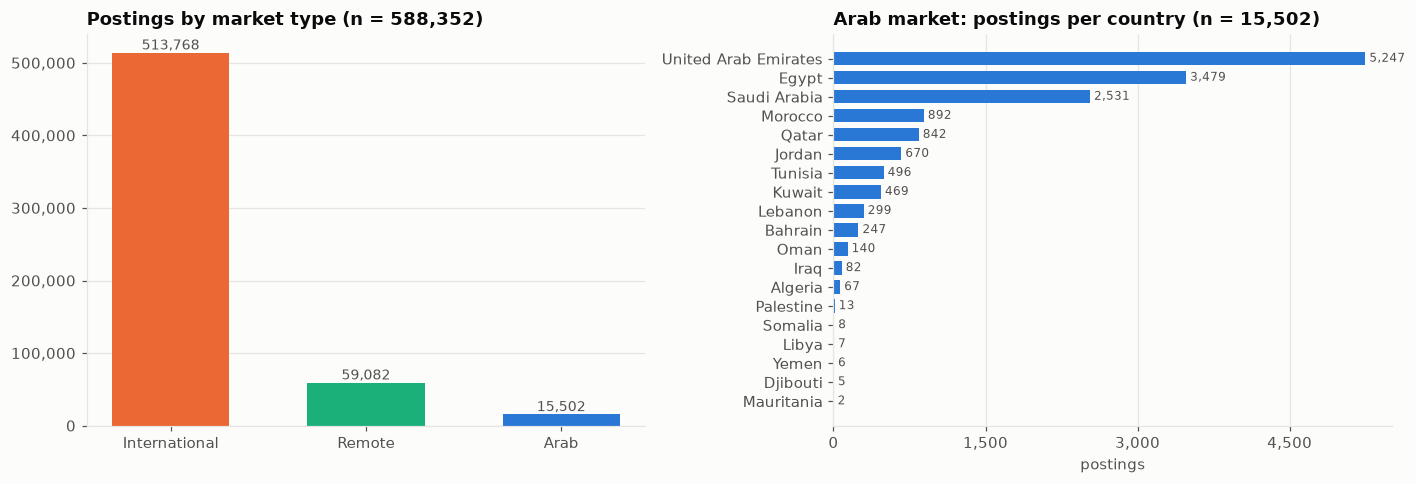

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
mt = df["market_type"].value_counts().drop("Unknown", errors="ignore")
axes[0].bar(mt.index, mt.values, color=[MARKET_COLORS[m] for m in mt.index], width=0.6)
for x, v in enumerate(mt.values):
    axes[0].text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=9, color=MUTED)
axes[0].set_title(f"Postings by market type (n = {mt.sum():,})"); axes[0].grid(axis="x", visible=False)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
arab = df[df["market_type"].eq("Arab")]["country"].value_counts()
hbar(arab, f"Arab market: postings per country (n = {arab.sum():,})", ax=axes[1], color=MARKET_COLORS["Arab"])
plt.tight_layout(); plt.show()

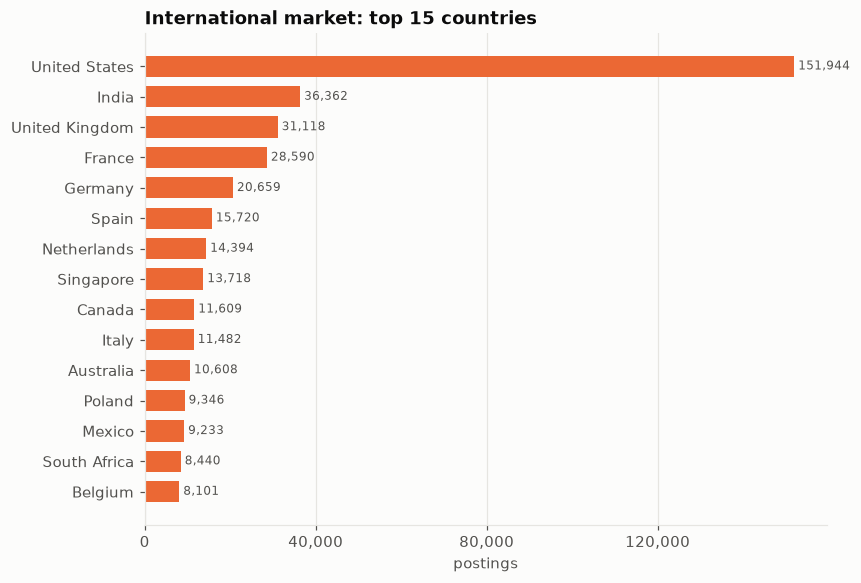

In [17]:
hbar(df[df["market_type"].eq("International")]["country"].value_counts().head(15),
     "International market: top 15 countries", color=MARKET_COLORS["International"]); plt.show()

**Findings.** The Arab market is small in this sample (~15k postings), dominated by the **UAE, Saudi Arabia
and Egypt**. Most international postings are in the US, India and Western Europe. Remember the sample-size
warning (risk R2): Arab vs. international comparisons are *exploratory*.

## B2. Which roles?

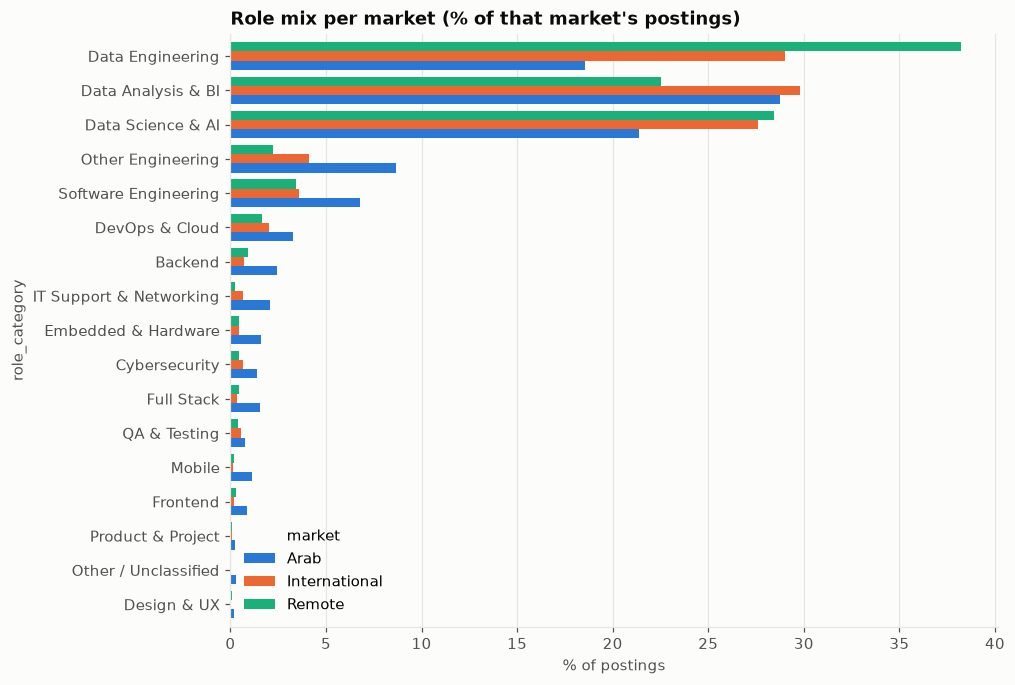

In [18]:
role_mkt = pd.crosstab(df["role_category"], df["market_type"], normalize="columns")[list(MARKET_COLORS)] * 100
role_mkt = role_mkt.loc[role_mkt.mean(axis=1).sort_values().index]
ax = role_mkt.plot.barh(figsize=(9, 7), color=MARKET_COLORS, width=0.8)
ax.set_title("Role mix per market (% of that market's postings)"); ax.set_xlabel("% of postings")
ax.grid(axis="y", visible=False); ax.legend(title="market", frameon=False); plt.show()

**Finding.** The Kaggle data only covers data roles + software / cloud, so *Data Analysis*, *Data Engineering*
and *Data Science* dominate International and Remote. The Arab sources are broader (software, IT support,
engineering), so compare **within one role category** rather than raw totals.

## B3. Seniority, work mode, job type

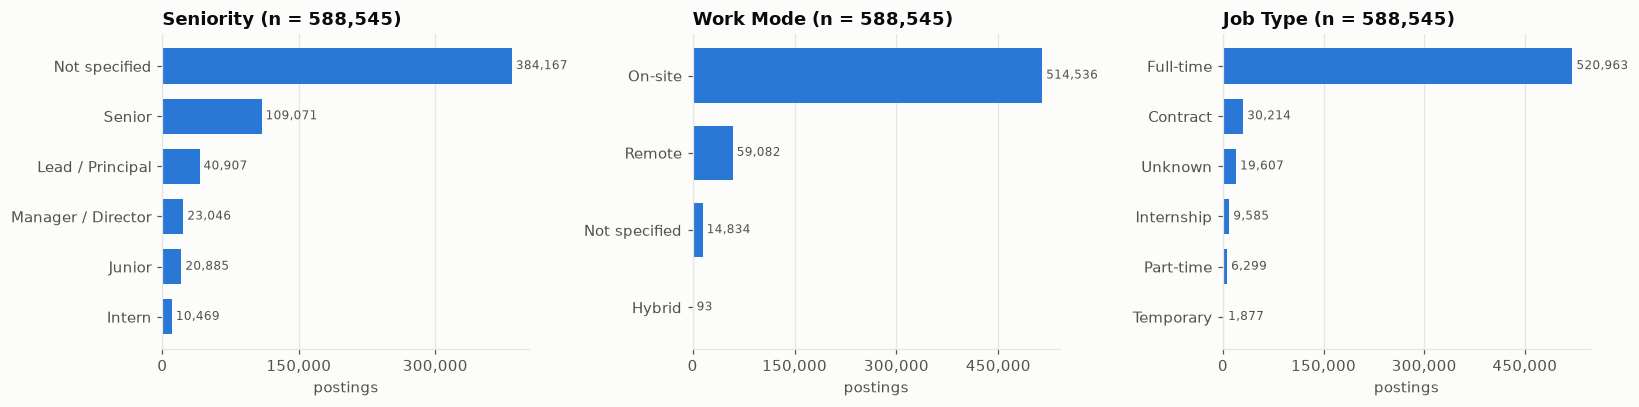

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["seniority", "work_mode", "job_type"]):
    hbar(df[col].value_counts(), f"{col.replace('_', ' ').title()} (n = {len(df):,})", ax=ax)
plt.tight_layout(); plt.show()

## B4. Most requested skills (US-03)

Strict view: only postings whose skills were **not** enriched by the team, i.e. skills actually written in
the posting / source.

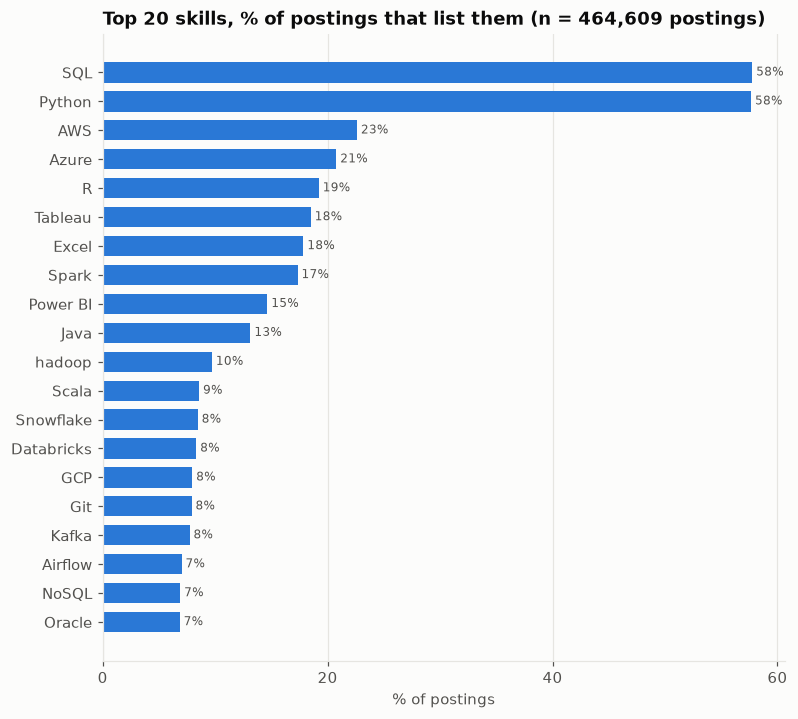

In [20]:
strict_ids = df.loc[~df["skills_enriched"], ["job_id", "market_type"]]
sk = skills.merge(strict_ids, on="job_id")
n_jobs = sk["job_id"].nunique()
top = sk["skill"].value_counts().head(20) / n_jobs * 100
hbar(top, f"Top 20 skills, % of postings that list them (n = {n_jobs:,} postings)", xlabel="% of postings", fmt="{:.0f}%")
plt.show()

## B5. Skills gap: Arab vs International vs Remote (US-04, FR-16)

In [21]:
MIN_POSTINGS = 100   # FR-16: flag groups that are too small
share = {}
for market in MARKET_COLORS:
    ids = df.loc[df["market_type"].eq(market) & df["skills_count"].gt(0), "job_id"]
    status = "OK" if len(ids) >= MIN_POSTINGS else "TOO FEW POSTINGS"
    print(f"{market:<14} {len(ids):>8,} postings with skills  -> {status}")
    share[market] = skills[skills["job_id"].isin(ids)]["skill"].value_counts() / len(ids) * 100
gap = pd.DataFrame(share).fillna(0)
top_skills = gap.max(axis=1).sort_values(ascending=False).head(15).index
gap.loc[top_skills].round(1).style.background_gradient(cmap="Blues", axis=None).format("{:.1f}%")

Arab             15,500 postings with skills  -> OK


International   442,885 postings with skills  -> OK


Remote           55,097 postings with skills  -> OK


,Arab,International,Remote
skill,,,
Python,88.9%,59.3%,66.9%
SQL,83.1%,58.5%,64.8%
Excel,40.0%,17.9%,13.9%
Tableau,33.0%,18.2%,18.0%
AWS,18.0%,23.6%,30.2%
Power BI,28.3%,14.5%,12.0%
Java,25.3%,14.7%,15.0%
Azure,16.4%,20.3%,22.4%
Spark,21.3%,17.8%,22.1%


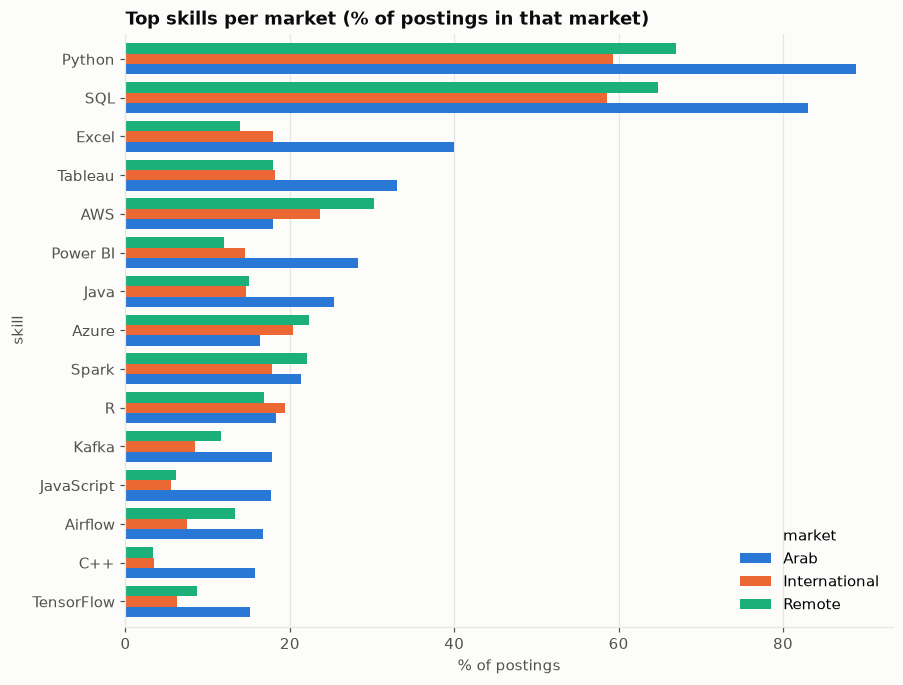

In [22]:
g = gap.loc[top_skills[::-1]]
ax = g.plot.barh(figsize=(9, 7), color=MARKET_COLORS, width=0.8)
ax.set_title("Top skills per market (% of postings in that market)"); ax.set_xlabel("% of postings")
ax.grid(axis="y", visible=False); ax.legend(title="market", frameon=False); plt.show()

In [23]:
# Skills relatively more / less requested in the Arab market than internationally (min. 3% share)
diff = (gap["Arab"] - gap["International"])[gap["Arab"] >= 3].sort_values()
pd.concat([diff.head(8), diff.tail(8)]).round(1).to_frame("Arab minus International (pp)")

,Arab minus International (pp)
skill,
AWS,-5.7
Azure,-3.9
Scala,-3.5
sas,-2.7
SQL Server,-2.1
Go,-1.7
GCP,-1.6
Oracle,-1.5
C++,12.3


**Note.** Arab-market skills include enriched (team-added) skills because almost all Arab rows were
enriched; treat the gap as indicative, not exact.

## B6. Salaries (posted pay only, FR-17)

33,586 postings with a posted salary (5.7% of all)


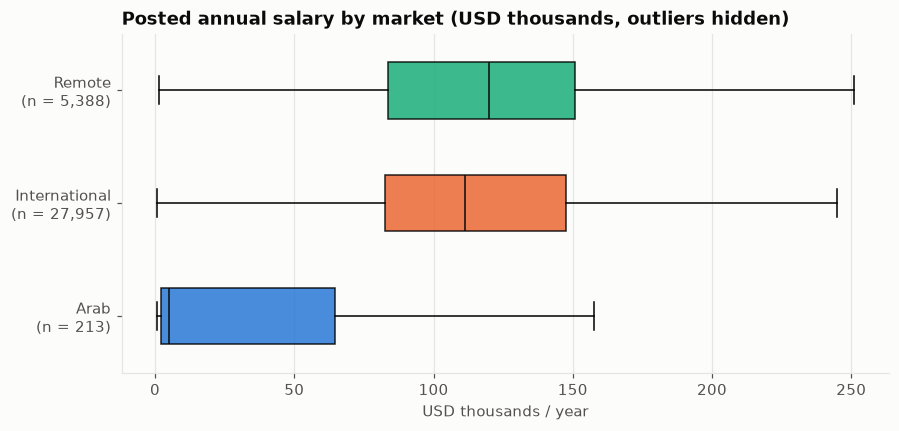

,count,mean,std,min,25%,50%,75%,max
market_type,,,,,,,,
Arab,213.0,34004.0,48341.0,557.0,2227.0,5042.0,64800.0,249000.0
International,27957.0,116912.0,51653.0,800.0,82420.0,111175.0,147500.0,960000.0
Remote,5388.0,121125.0,53693.0,1300.0,83500.0,120000.0,150800.0,650000.0
Unknown,28.0,171907.0,87230.0,43000.0,123500.0,156750.0,175500.0,425000.0


In [24]:
pay = df[df["salary_usd_annual"].notna() & ~df["salary_is_estimate"]]
print(f"{len(pay):,} postings with a posted salary ({len(pay) / len(df):.1%} of all)")
fig, ax = plt.subplots(figsize=(9, 4))
data = [pay.loc[pay["market_type"].eq(m), "salary_usd_annual"] / 1000 for m in MARKET_COLORS]
bp = ax.boxplot(data, orientation="horizontal", tick_labels=[f"{m}\n(n = {len(d):,})" for m, d in zip(MARKET_COLORS, data)],
                patch_artist=True, showfliers=False, widths=0.5, medianprops={"color": INK})
for patch, c in zip(bp["boxes"], MARKET_COLORS.values()):
    patch.set_facecolor(c); patch.set_alpha(0.85)
ax.set_title("Posted annual salary by market (USD thousands, outliers hidden)"); ax.set_xlabel("USD thousands / year")
ax.grid(axis="y", visible=False); plt.show()
pay.groupby("market_type")["salary_usd_annual"].describe().round(0)

**Caveats.** Only a small share of postings carries a real salary and the Arab group is very small.
Conversion rates are approximate (`USD_PER_UNIT` in `clean_utils.py`). Do not compare Arab vs international
pay without adjusting for cost of living.

## B7. Time coverage and duplicates

In [25]:
pd.crosstab(df["source_dataset"], df["posted_year"].fillna(0).astype(int).astype(str).replace("0", "unknown"))

posted_year,2021,2022,2023,2024,2025,2026,unknown
source_dataset,,,,,,,
all_tech_jobs,3,10,21,8,58,980,2455
arab_jobs,0,0,0,1,2,71,342
cybersecurity_manual,0,0,0,0,0,0,58
jooble_careerjet_foreign,0,0,0,0,1,9100,0
kaggle_2023_arab_search,0,0,31600,0,0,0,0
kaggle_2023_international,0,0,539403,0,0,0,0
remote_boards,0,0,0,2,0,136,868
startup_jobs,0,0,0,0,0,3426,0


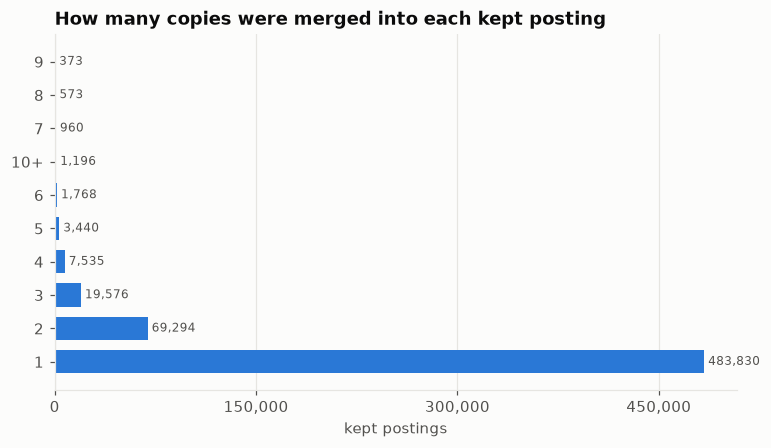

In [26]:
hbar(df["duplicate_count"].clip(upper=10).value_counts().sort_index().rename(lambda x: "10+" if x == 10 else str(x)),
     "How many copies were merged into each kept posting", xlabel="kept postings")
plt.gca().invert_yaxis(); plt.show()

---
## Summary

| Area | What we found in the raw data | What the cleaning does |
|---|---|---|
| Size | 775k rows, 91 % from one Kaggle 2023 dataset | analyses split by `market_type` / `source_dataset` |
| Duplicates | ~24 % near-duplicates across boards & keywords | keep best copy, `sources` + `duplicate_count` |
| Country | 'Sudan' = search location for 21k US jobs; missing countries | use real location; parse country from location text |
| Formats | ~100 job-type spellings, mixed salary text, several skill-list formats | standard categories, parsed salary → annual USD, canonical skills |
| Provenance | many salaries are benchmarks, many skills were added | `salary_is_estimate`, `skills_enriched` flags |
| Text | mojibake, emails/phones, Arabic variants | ftfy, PII removal, Arabic normalization |
| Time | 2023 (Kaggle) vs Oct 2026 (APIs) | `posted_year` column — filter before trend analysis |

Next steps (WP5–WP7): skill extraction from descriptions, role classifier, dashboard.